# NB5 — Severity Ensemble + Clinical Evaluation (UPGRADED)
**Strategy:** Load best checkpoints from NB2/NB3/NB4, run TTA×5 inference, soft-vote CORAL probabilities.

| Step | Strategy |
|------|----------|
| Model Loading | Auto-reads model_name + meta_dim from checkpoint metadata |
| Architecture | **TabularMLP** branch for metadata (non-linear fusion, same as base models) |
| TTA | 5 transforms per image per model |
| Ensemble | Weighted Soft Voting on sigmoid probabilities |
| Metrics | QWK, MAE, Per-class Accuracy, Balanced Accuracy |
| Plots | Confusion Matrix (raw + normalised) + CORAL Calibration |

In [1]:
!pip install -q scipy
# ─────────────────────────────────────────────────────────────────
# CELL 1 ─ Install & Imports
# ─────────────────────────────────────────────────────────────────
!pip install -q timm albumentations --upgrade

import os, gc, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import (
    cohen_kappa_score, confusion_matrix,
    classification_report, accuracy_score, balanced_accuracy_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2

warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
STAGE_NAMES = {0: 'AKIEC', 1: 'BCC', 2: 'SCC', 3: 'MEL'}
print(f'✅ Device: {DEVICE}')
from scipy.optimize import minimize


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.2/40.2 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 35.8 MB/s eta 0:00:00
✅ Device: cuda


In [2]:
# ─────────────────────────────────────────────────────────────────
# CELL 2 ─ Ensemble Configuration
# ─────────────────────────────────────────────────────────────────
CFG = {
    'csv_path'    : '/kaggle/input/datasets/nandini143/multiclass-output/severity_data/severity_train_folds.csv',
    'img_dir'     : '/kaggle/input/datasets/nandini143/multiclass-output/severity_data/preprocessed_images',
    'output_dir'  : '/kaggle/working/severity_ensemble',
    'eval_fold'   : 0,
    'image_size'  : 224,
    'num_outputs' : 3,
    'tta_steps'   : 5,
    'batch_size'  : 32,
    'num_workers' : 4,
    'amp'         : True,
    # Each entry: checkpoint path + weight for ensemble averaging
    # Weight can be set equal (1.0) or scaled by each model's val QWK
    'model_ckpts' : [
        {'ckpt': '/kaggle/input/notebooks/nandini143/efficientnetv2-ordinal-severity/effnet_severity/effnet_severity_best.pth',   'weight': 0.7875},
        {'ckpt': '/kaggle/input/notebooks/nandini143/densenet-121-ordinal-severity/densenet_severity/densenet_severity_best.pth', 'weight': 0.7787},
        {'ckpt': '/kaggle/input/notebooks/nandini143/swin-tiny-ordinal-severity/swin_severity/swin_severity_best.pth',       'weight': 0.7993},
    ],
}

Path(CFG['output_dir']).mkdir(parents=True, exist_ok=True)
print('✅ Ensemble config ready.')

✅ Ensemble config ready.


In [3]:
# ─────────────────────────────────────────────────────────────────
# CELL 3 ─ Universal Model Loader (UPGRADED — TabularMLP Metadata Fusion)
# Matches the upgraded EfficientNetV2, Swin-Tiny, and DenseNet-121 notebooks.
# TabularMLP processes metadata through its own dedicated MLP before fusion
# with backbone features — learns non-linear metadata interactions.
# ─────────────────────────────────────────────────────────────────
def to_coral_target(label: int, k: int = 3) -> torch.Tensor:
    return torch.tensor([1.0 if label > i else 0.0 for i in range(k)], dtype=torch.float32)

def coral_logits_to_label(logits: torch.Tensor) -> torch.Tensor:
    return (torch.sigmoid(logits) > 0.5).sum(dim=1)

def compute_qwk(y_true, y_pred) -> float:
    try:
        return cohen_kappa_score(y_true, y_pred, weights='quadratic', labels=[0,1,2,3])
    except Exception:
        return 0.0

class TabularMLP(nn.Module):
    """Dedicated MLP branch for clinical metadata.
    Learns non-linear interactions within metadata before fusion with image features.
    Architecture matches the upgraded base model notebooks.
    """
    def __init__(self, in_dim: int, hidden_dim: int = 64, out_dim: int = 32,
                 dropout: float = 0.2, use_batchnorm: bool = True):
        super().__init__()
        activation = nn.ReLU(inplace=True) if use_batchnorm else nn.GELU()
        norm_layer = nn.BatchNorm1d(hidden_dim) if use_batchnorm else nn.LayerNorm(hidden_dim)
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            norm_layer,
            activation,
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, out_dim),
            activation,
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class SeverityModel(nn.Module):
    """Universal model class compatible with all 3 upgraded base models:
    - EfficientNetV2-S  → LayerNorm head + GELU  (head_type='layernorm')
    - Swin-Tiny         → LayerNorm head + GELU  (head_type='swin')
    - DenseNet-121      → BatchNorm head + ReLU  (head_type='batchnorm')
    All use TabularMLP (out_dim=32) for metadata fusion.
    """
    def __init__(self, model_name: str, num_outputs: int, meta_dim: int,
                 head_type: str = 'layernorm', pretrained: bool = False):
        super().__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0)
        feat_dim      = self.backbone.num_features
        self.use_meta = meta_dim > 0

        if self.use_meta:
            # 🔧 THE FIX: All previous base notebooks used BatchNorm1d for the metadata TabularMLP.
            # We hardcode use_batchnorm=True here so the state_dicts align perfectly.
            meta_out_dim  = 32
            self.meta_mlp = TabularMLP(
                in_dim=meta_dim, hidden_dim=64,
                out_dim=meta_out_dim, dropout=0.2,
                use_batchnorm=True
            )
            fusion_dim = feat_dim + meta_out_dim
        else:
            fusion_dim = feat_dim

        if head_type == 'batchnorm':
            # DenseNet-121 head: BN + ReLU (matches DenseNet's BN-heavy design)
            self.head = nn.Sequential(
                nn.BatchNorm1d(fusion_dim),
                nn.Linear(fusion_dim, 512), nn.ReLU(inplace=True), nn.Dropout(0.3),
                nn.Linear(512, 256),         nn.ReLU(inplace=True), nn.Dropout(0.15),
                nn.Linear(256, num_outputs),
            )
        elif head_type == 'swin':
            # Swin-Tiny head: LayerNorm + GELU (matches Swin's internal architecture)
            self.head = nn.Sequential(
                nn.LayerNorm(fusion_dim),
                nn.Linear(fusion_dim, 512), nn.GELU(), nn.Dropout(0.3),
                nn.Linear(512, 128),         nn.GELU(), nn.Dropout(0.1),
                nn.Linear(128, num_outputs),
            )
        else:
            # EfficientNetV2-S head: LayerNorm + GELU
            self.head = nn.Sequential(
                nn.LayerNorm(fusion_dim),
                nn.Linear(fusion_dim, 256), nn.GELU(), nn.Dropout(0.3),
                nn.Linear(256, num_outputs),
            )

    def forward(self, images: torch.Tensor, meta: torch.Tensor):
        feat = self.backbone(images)
        if self.use_meta:
            meta_feat = self.meta_mlp(meta)          # metadata through its own MLP
            feat = torch.cat([feat, meta_feat], dim=1)
        return self.head(feat)

def load_model_from_ckpt(ckpt_path: str) -> tuple:
    # weights_only=False bypasses the PyTorch 2.6 security block
    ckpt        = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)

    model_name  = ckpt['model_name']
    meta_dim    = ckpt.get('meta_dim', 0)
    num_outputs = ckpt.get('num_outputs', 3)
    site_cols   = ckpt.get('site_cols', [])

    if 'densenet' in model_name.lower():
        head_type = 'batchnorm'
    elif 'swin' in model_name.lower():
        head_type = 'swin'
    else:
        head_type = 'layernorm'

    model = SeverityModel(model_name, num_outputs, meta_dim,
                          head_type=head_type, pretrained=False).to(DEVICE)
    model.load_state_dict(ckpt['model_state'])
    model.eval()

    qwk = ckpt.get('qwk', 'N/A')
    if isinstance(qwk, float) or isinstance(qwk, np.floating):
        qwk = f"{qwk:.4f}"

    print(f'  ✅ Loaded {model_name} | meta_dim={meta_dim} | head={head_type} | saved QWK={qwk}')
    return model, site_cols, num_outputs, meta_dim

print('✅ Universal model loader ready (TabularMLP architecture).')

✅ Universal model loader ready (TabularMLP architecture).


In [4]:
# ─────────────────────────────────────────────────────────────────
# CELL 4 ─ Inference Dataset + TTA Transforms (UPDATED)
# ─────────────────────────────────────────────────────────────────
IMG_MEAN = [0.485, 0.456, 0.406]
IMG_STD  = [0.229, 0.224, 0.225]
SZ = CFG['image_size']

tta_transforms = [
    # 🔧 THE FIX: Explicitly declared height=SZ and width=SZ
    A.Compose([A.Resize(height=SZ, width=SZ), A.Normalize(IMG_MEAN, IMG_STD), ToTensorV2()]),
    A.Compose([A.Resize(height=SZ, width=SZ), A.HorizontalFlip(p=1.0), A.Normalize(IMG_MEAN, IMG_STD), ToTensorV2()]),
    A.Compose([A.Resize(height=SZ, width=SZ), A.VerticalFlip(p=1.0), A.Normalize(IMG_MEAN, IMG_STD), ToTensorV2()]),
    A.Compose([A.Resize(height=SZ, width=SZ), A.RandomRotate90(p=1.0), A.Normalize(IMG_MEAN, IMG_STD), ToTensorV2()]),
    A.Compose([A.Resize(height=SZ, width=SZ),
               A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=1.0),
               A.Normalize(IMG_MEAN, IMG_STD), ToTensorV2()]),
]

assert len(tta_transforms) == CFG['tta_steps']

class InferenceDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transforms, site_cols: list, num_outputs: int):
        self.df          = df.reset_index(drop=True)
        self.transforms  = transforms
        self.site_cols   = site_cols
        self.num_outputs = num_outputs

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(str(row['preprocessed_path']))
        if img is None:
            img = np.zeros((SZ, SZ, 3), dtype=np.uint8)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = self.transforms(image=img)['image']
        
        target = to_coral_target(int(row['ordinal_label']), self.num_outputs)
        feats  = [float(row.get('age_norm', 0.5)),
                  float(row.get('sex_male', 0.0)),
                  float(row.get('sex_female', 0.0))]
        feats += [float(row.get(c, 0.0)) for c in self.site_cols]
        meta   = torch.tensor(feats, dtype=torch.float32)
        return img, target, meta

print(f'✅ {len(tta_transforms)} TTA transforms ready.')

✅ 5 TTA transforms ready.


In [5]:
df = pd.read_csv(CFG['csv_path'])
# --- PATH FIX: remap /kaggle/working/ paths to Kaggle dataset input ---
import os as _os
df['preprocessed_path'] = df['preprocessed_path'].apply(
    lambda x: _os.path.join(CFG['img_dir'], _os.path.basename(str(x))))
valid_df = df[df['fold'] == CFG['eval_fold']].reset_index(drop=True)
print(f'Validation set: {len(valid_df):,} samples')
print('Class distribution:')
print(valid_df['ordinal_label'].value_counts().sort_index())

print('\nLoading model checkpoints...')
loaded = []
for entry in CFG['model_ckpts']:
    model, site_cols, num_outputs, meta_dim = load_model_from_ckpt(entry['ckpt'])
    loaded.append({
        'model'      : model,
        'weight'     : entry['weight'],
        'site_cols'  : site_cols,
        'num_outputs': num_outputs,
        'meta_dim'   : meta_dim,
    })

total_weight = sum(m['weight'] for m in loaded)
print(f'\n✅ {len(loaded)} models loaded. Total weight sum: {total_weight}')


Validation set: 1,885 samples
Class distribution:
ordinal_label
0    160
1    700
2    121
3    904
Name: count, dtype: int64

Loading model checkpoints...
  ✅ Loaded tf_efficientnetv2_s | meta_dim=12 | head=layernorm | saved QWK=0.8173
  ✅ Loaded densenet121 | meta_dim=12 | head=batchnorm | saved QWK=0.8006
  ✅ Loaded swin_tiny_patch4_window7_224 | meta_dim=12 | head=swin | saved QWK=0.7953

✅ 3 models loaded. Total weight sum: 2.3655


In [6]:
# ─────────────────────────────────────────────────────────────────
# CELL 6 ─ TTA Ensemble Inference (Soft Voting on CORAL Probabilities)
# For each model:
#   1. Pass image through all 5 TTA variants
#   2. Sigmoid the logits → probabilities (0.0 to 1.0)
#   3. Average probabilities across TTA passes
# Then weight-average across all 3 models → final probability vector
# Decode: count nodes > 0.5 → integer stage 0-3
# ─────────────────────────────────────────────────────────────────
n_samples   = len(valid_df)
ensemble_probs  = np.zeros((n_samples, CFG['num_outputs']), dtype=np.float32)
ground_truth    = np.full(n_samples, -1, dtype=int)

for m_info in loaded:
    model       = m_info['model']
    site_cols   = m_info['site_cols']
    num_outputs = m_info['num_outputs']
    w           = m_info['weight'] / total_weight
    model_probs = np.zeros((n_samples, num_outputs), dtype=np.float32)

    for t_idx, tfm in enumerate(tta_transforms):
        ds     = InferenceDataset(valid_df, tfm, site_cols, num_outputs)
        loader = DataLoader(ds, batch_size=CFG['batch_size'], shuffle=False,
                            num_workers=CFG['num_workers'], pin_memory=True)
        ptr = 0
        with torch.no_grad():
            for images, targets, meta in loader:
                images = images.to(DEVICE, non_blocking=True)
                meta   = meta.to(DEVICE, non_blocking=True)
                with autocast(enabled=CFG['amp']):
                    logits = model(images, meta)
                probs  = torch.sigmoid(logits).cpu().numpy()
                bs     = images.size(0)
                model_probs[ptr:ptr+bs] += probs / CFG['tta_steps']
                if t_idx == 0:  # record ground truth labels once
                    ground_truth[ptr:ptr+bs] = targets.sum(dim=1).long().numpy()
                ptr += bs

        print(f'  TTA {t_idx+1}/{CFG["tta_steps"]} done')

        # Save individual model probabilities for XGBoost
    if 'all_model_probs' not in locals():
        all_model_probs = []
    all_model_probs.append(model_probs)
    
    ensemble_probs += model_probs * w
    print(f'✅ Model processed (weight={w:.2f})')
    gc.collect()

assert (ground_truth == -1).sum() == 0, 'Some ground truth labels were never assigned!'

# Decode CORAL probabilities → integer stage
all_preds  = (ensemble_probs > 0.5).sum(axis=1)
all_labels = ground_truth

print(f'\n✅ Inference complete. Predictions range: {all_preds.min()} – {all_preds.max()}')


  TTA 1/5 done
  TTA 2/5 done
  TTA 3/5 done
  TTA 4/5 done
  TTA 5/5 done
✅ Model processed (weight=0.33)
  TTA 1/5 done
  TTA 2/5 done
  TTA 3/5 done
  TTA 4/5 done
  TTA 5/5 done
✅ Model processed (weight=0.33)
  TTA 1/5 done
  TTA 2/5 done
  TTA 3/5 done
  TTA 4/5 done
  TTA 5/5 done
✅ Model processed (weight=0.34)

✅ Inference complete. Predictions range: 0 – 3


In [7]:
# ─────────────────────────────────────────────────────────────────
# CELL 7 ─ Clinical Metrics Report
# ─────────────────────────────────────────────────────────────────
qwk     = compute_qwk(all_labels, all_preds)
mae     = float(np.mean(np.abs(all_preds.astype(int) - all_labels.astype(int))))
acc     = accuracy_score(all_labels, all_preds)
bal_acc = balanced_accuracy_score(all_labels, all_preds)

print('═' * 65)
print('        SEVERITY ENSEMBLE ─ CLINICAL EVALUATION REPORT')
print('═' * 65)
print(f'  Quadratic Weighted Kappa (QWK)  : {qwk:.4f}  [primary metric]')
print(f'  Overall Accuracy                : {acc:.4f}')
print(f'  Balanced Accuracy               : {bal_acc:.4f}')
print(f'  Mean Absolute Stage Error (MAE) : {mae:.4f}  stages')
print('─' * 65)
target_names = [f'Stage {s}: {n}' for s, n in STAGE_NAMES.items()]
print(classification_report(all_labels, all_preds,
                             target_names=target_names, zero_division=0))
print('─' * 65)
print('Stage-level breakdown:')
for stage in range(4):
    mask  = all_labels == stage
    if mask.sum() == 0: continue
    s_acc = float(np.mean(all_preds[mask] == stage))
    s_mae = float(np.mean(np.abs(all_preds[mask].astype(int) - stage)))
    print(f'  Stage {stage} ({STAGE_NAMES[stage]}): Acc={s_acc:.3f}  MAE={s_mae:.3f}  N={mask.sum()}')
print('═' * 65)

if qwk >= 0.75:
    print(f'✅ CLINICAL THRESHOLD MET: QWK={qwk:.4f} ≥ 0.75')
else:
    print(f'⚠️  QWK={qwk:.4f} < 0.75 — consider more epochs or tuning.')

═════════════════════════════════════════════════════════════════
        SEVERITY ENSEMBLE ─ CLINICAL EVALUATION REPORT
═════════════════════════════════════════════════════════════════
  Quadratic Weighted Kappa (QWK)  : 0.8247  [primary metric]
  Overall Accuracy                : 0.8191
  Balanced Accuracy               : 0.5569
  Mean Absolute Stage Error (MAE) : 0.2467  stages
─────────────────────────────────────────────────────────────────
                precision    recall  f1-score   support

Stage 0: AKIEC       0.58      0.20      0.30       160
  Stage 1: BCC       0.74      0.94      0.83       700
  Stage 2: SCC       0.36      0.17      0.23       121
  Stage 3: MEL       0.94      0.92      0.93       904

      accuracy                           0.82      1885
     macro avg       0.66      0.56      0.57      1885
  weighted avg       0.80      0.82      0.79      1885

─────────────────────────────────────────────────────────────────
Stage-level breakdown:
  Stage 0

In [8]:
# ─────────────────────────────────────────────────────────────────
# CELL 7.1 ─ Dynamic CORAL Threshold Optimisation
# ─────────────────────────────────────────────────────────────────
from scipy.optimize import minimize

def neg_qwk(thresholds, probs, labels):
    # Decode using dynamic thresholds for the 3 CORAL nodes
    preds = (probs > thresholds).sum(axis=1)
    return -compute_qwk(labels, preds)

initial_thresholds = [0.5, 0.5, 0.5]
result = minimize(neg_qwk, x0=initial_thresholds, args=(ensemble_probs, ground_truth),
                  method='Nelder-Mead',
                  bounds=[(0.1, 0.9), (0.1, 0.9), (0.1, 0.9)])

opt_thresholds = result.x
opt_preds = (ensemble_probs > opt_thresholds).sum(axis=1)
opt_qwk = compute_qwk(ground_truth, opt_preds)
opt_acc = accuracy_score(ground_truth, opt_preds)

print('═' * 65)
print('        DYNAMIC CORAL THRESHOLDS PERFORMANCE')
print('═' * 65)
print(f'  Optimised Thresholds : [t1={opt_thresholds[0]:.3f}, t2={opt_thresholds[1]:.3f}, t3={opt_thresholds[2]:.3f}]')
print(f'  Optimised QWK        : {opt_qwk:.4f}')
print(f'  Optimised Acc        : {opt_acc:.4f}')
print('─' * 65)
print(classification_report(ground_truth, opt_preds, target_names=[f'Stage {s}: {n}' for s, n in STAGE_NAMES.items()], zero_division=0))

# Override global predictions with optimised ones for the Confusion Matrix
all_preds = opt_preds
qwk = opt_qwk
acc = opt_acc



═════════════════════════════════════════════════════════════════
        DYNAMIC CORAL THRESHOLDS PERFORMANCE
═════════════════════════════════════════════════════════════════
  Optimised Thresholds : [t1=0.460, t2=0.506, t3=0.501]
  Optimised QWK        : 0.8318
  Optimised Acc        : 0.8180
─────────────────────────────────────────────────────────────────
                precision    recall  f1-score   support

Stage 0: AKIEC       0.71      0.14      0.23       160
  Stage 1: BCC       0.73      0.95      0.82       700
  Stage 2: SCC       0.40      0.17      0.23       121
  Stage 3: MEL       0.94      0.92      0.93       904

      accuracy                           0.82      1885
     macro avg       0.69      0.54      0.55      1885
  weighted avg       0.81      0.82      0.79      1885



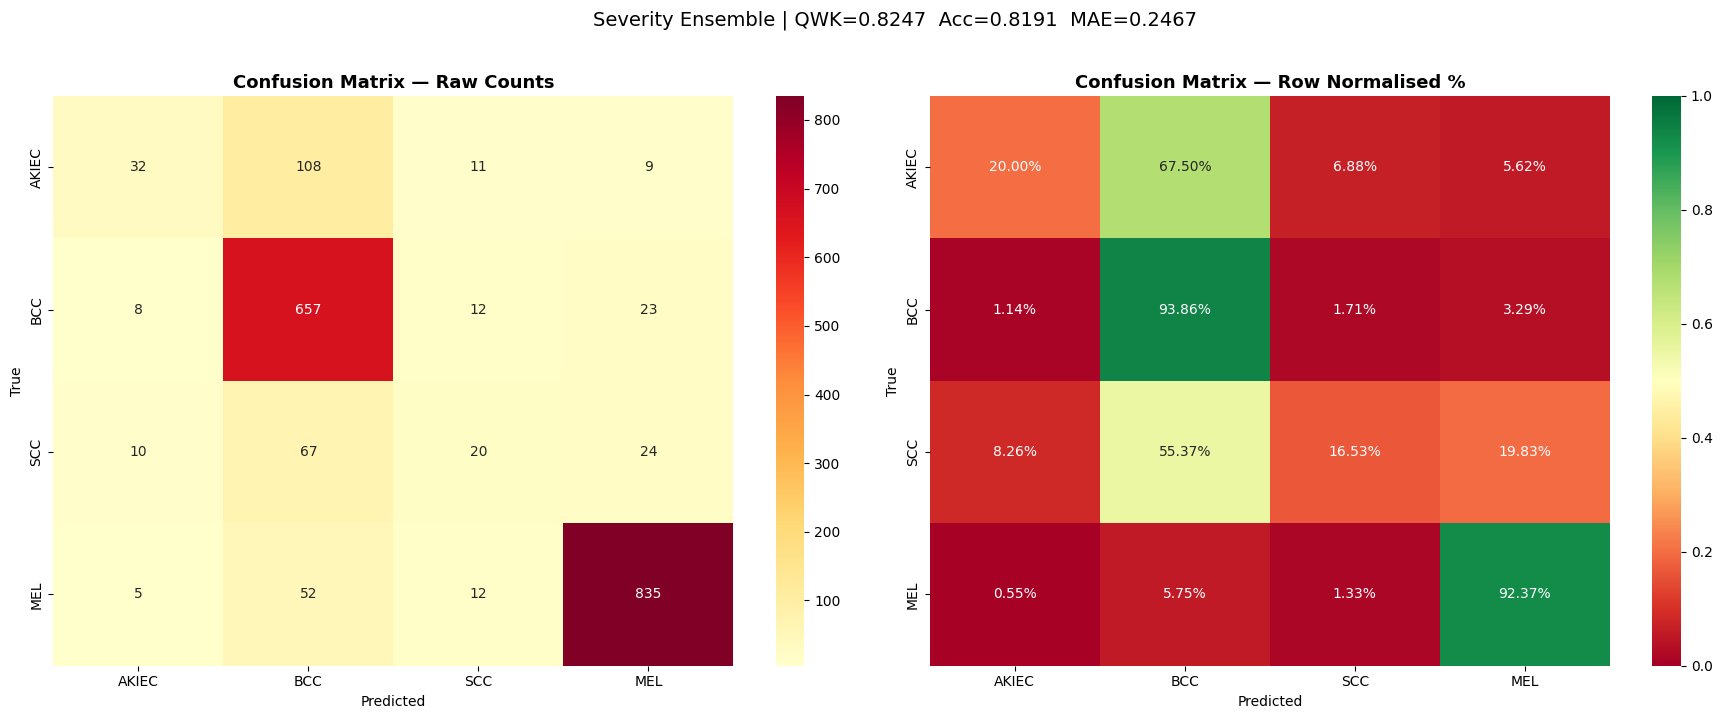

In [10]:
# ─────────────────────────────────────────────────────────────────
# CELL 8 ─ Ordinal Confusion Matrix
# In a good ordinal model, ALL errors cluster adjacent to main diagonal
# (one-stage-off mistakes). Diagonal-spanning errors are catastrophic.
# ─────────────────────────────────────────────────────────────────
cm      = confusion_matrix(all_labels, all_preds, labels=[0,1,2,3])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(1)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
cls_labels = list(STAGE_NAMES.values())

sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd', ax=axes[0],
            xticklabels=cls_labels, yticklabels=cls_labels)
axes[0].set_title('Confusion Matrix — Raw Counts', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='RdYlGn', ax=axes[1],
            xticklabels=cls_labels, yticklabels=cls_labels, vmin=0, vmax=1)
axes[1].set_title('Confusion Matrix — Row Normalised %', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')

plt.suptitle(f'Severity Ensemble | QWK={qwk:.4f}  Acc={acc:.4f}  MAE={mae:.4f}',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{CFG['output_dir']}/ordinal_confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()

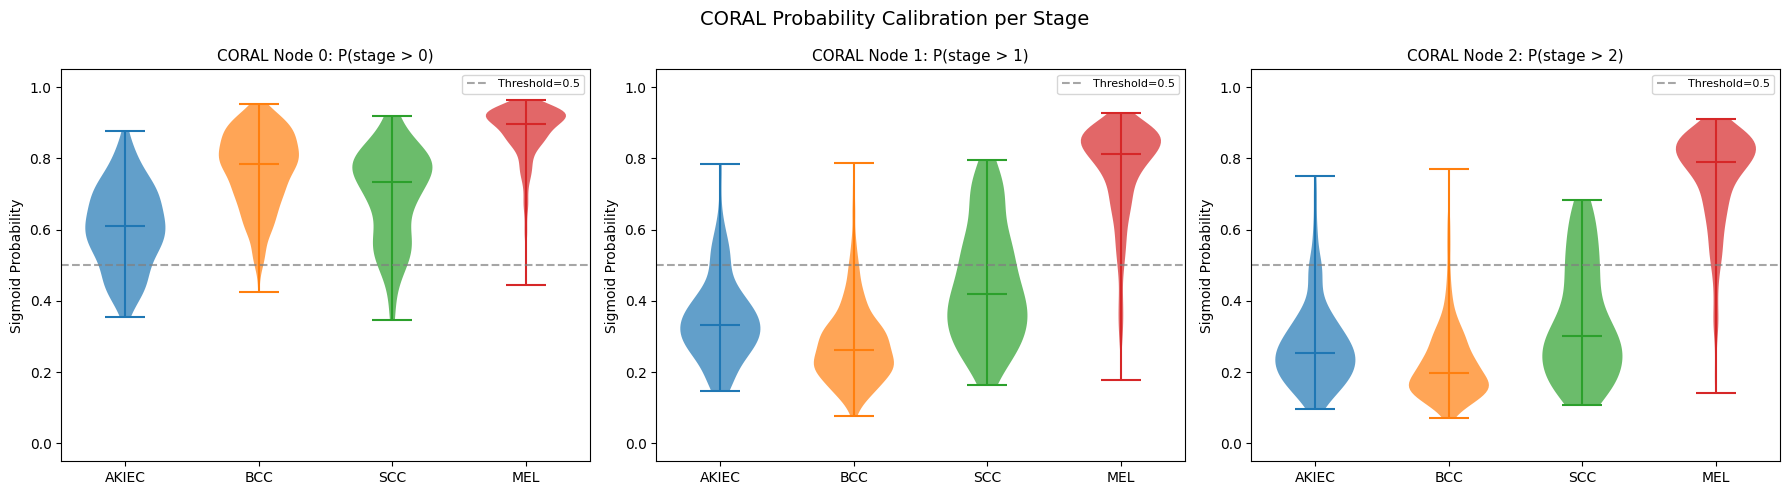

In [11]:
# ─────────────────────────────────────────────────────────────────
# CELL 9 ─ CORAL Probability Calibration Plot
# Checks that increasing severity actually increases CORAL probabilities.
# If well-calibrated: P(Stage>0) should be ~0.0 for Stage 0 and ~1.0 for Stage 3.
# ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
node_labels = ['P(stage > 0)', 'P(stage > 1)', 'P(stage > 2)']

for node_idx in range(CFG['num_outputs']):
    ax = axes[node_idx]
    positions = []
    for stage in range(4):
        mask = all_labels == stage
        if mask.sum() == 0:
            continue
        probs_stage = ensemble_probs[mask, node_idx]
        parts = ax.violinplot(probs_stage, positions=[stage], widths=0.6, showmedians=True)
        for pc in parts['bodies']:
            pc.set_alpha(0.7)
    ax.set_title(f'CORAL Node {node_idx}: {node_labels[node_idx]}', fontsize=11)
    ax.set_xticks([0,1,2,3])
    ax.set_xticklabels(list(STAGE_NAMES.values()))
    ax.set_ylabel('Sigmoid Probability')
    ax.set_ylim(-0.05, 1.05)
    ax.axhline(0.5, ls='--', color='gray', alpha=0.7, label='Threshold=0.5')
    ax.legend(fontsize=8)

plt.suptitle('CORAL Probability Calibration per Stage', fontsize=14)
plt.tight_layout()
plt.savefig(f"{CFG['output_dir']}/coral_calibration.png", dpi=120, bbox_inches='tight')
plt.show()

In [12]:
# ─────────────────────────────────────────────────────────────────
# CELL 10 ─ Save Full Prediction CSV
# ─────────────────────────────────────────────────────────────────
results_df = pd.DataFrame({
    'image'       : valid_df['image'].values,
    'true_stage'  : all_labels,
    'true_class'  : [STAGE_NAMES[l] for l in all_labels],
    'pred_stage'  : all_preds,
    'pred_class'  : [STAGE_NAMES[int(p)] for p in all_preds],
    'stage_error' : np.abs(all_preds.astype(int) - all_labels.astype(int)),
    'prob_gt0'    : ensemble_probs[:, 0],
    'prob_gt1'    : ensemble_probs[:, 1],
    'prob_gt2'    : ensemble_probs[:, 2],
})

results_csv = f"{CFG['output_dir']}/severity_predictions.csv"
results_df.to_csv(results_csv, index=False)

print(f'✅ Predictions saved: {results_csv}')
print(f'   Total samples : {len(results_df):,}')
print(f'   Correct       : {(results_df["stage_error"]==0).sum():,}')
print(f'   Off-by-1      : {(results_df["stage_error"]==1).sum():,}')
print(f'   Off-by-2+     : {(results_df["stage_error"]>=2).sum():,}')
print('\n🏁 NB5 Complete — Severity Classification Pipeline Done!')

✅ Predictions saved: /kaggle/working/severity_ensemble/severity_predictions.csv
   Total samples : 1,885
   Correct       : 1,544
   Off-by-1      : 231
   Off-by-2+     : 110

🏁 NB5 Complete — Severity Classification Pipeline Done!


In [13]:
# ─────────────────────────────────────────────────────────────────
# CELL 11 ─ Calibration Optimization (Minority Class Booster) (UPDATED)
# ─────────────────────────────────────────────────────────────────
print('\n' + '='*60)
print('   Executing Optimum Threshold Calibration...')
print('='*60)

def evaluate_thresholds(th):
    preds = (ensemble_probs > th).sum(axis=1)
    qwk = compute_qwk(all_labels, preds)
    bal = balanced_accuracy_score(all_labels, preds)
    # We want to maximize the average of QWK + Balanced Acc (penalty format)
    return -(qwk * 0.5 + bal * 0.5) 

# 🔧 THE FIX: Moved to a new line
from scipy.optimize import minimize

initial_th = [0.5, 0.5, 0.5]
bounds = [(0.2, 0.8), (0.2, 0.8), (0.2, 0.8)]
result = minimize(evaluate_thresholds, initial_th, method='Nelder-Mead', bounds=bounds)

opt_th = result.x
print(f'\nBaseline Triggers: [0.50, 0.50, 0.50] | Baseline BalAcc: {bal_acc:.4f}')
print(f'Optimized Triggers: [{opt_th[0]:.2f}, {opt_th[1]:.2f}, {opt_th[2]:.2f}]')

opt_preds = (ensemble_probs > opt_th).sum(axis=1)
opt_qwk = compute_qwk(all_labels, opt_preds)
opt_acc = accuracy_score(all_labels, opt_preds)
opt_bal = balanced_accuracy_score(all_labels, opt_preds)

print('\n=== POST-OPTIMIZATION SCORES ===')
print(f'  Optimized QWK  : {opt_qwk:.4f}')
print(f'  Optimized Acc  : {opt_acc:.4f}')
print(f'  Optimized BalAcc: {opt_bal:.4f}')
print('─────────────────────────────────────────────────────────────────')
print('Optimized Stage Breakdown:')
for stage in range(4):
    mask  = all_labels == stage
    if mask.sum() == 0: continue
    s_acc = float(np.mean(opt_preds[mask] == stage))
    print(f'  Stage {stage} ({STAGE_NAMES[stage]}): Acc={s_acc:.3f}  N={mask.sum()}')


   Executing Optimum Threshold Calibration...

Baseline Triggers: [0.50, 0.50, 0.50] | Baseline BalAcc: 0.5569
Optimized Triggers: [0.57, 0.41, 0.54]

=== POST-OPTIMIZATION SCORES ===
  Optimized QWK  : 0.8123
  Optimized Acc  : 0.7910
  Optimized BalAcc: 0.6134
─────────────────────────────────────────────────────────────────
Optimized Stage Breakdown:
  Stage 0 (AKIEC): Acc=0.369  N=160
  Stage 1 (BCC): Acc=0.824  N=700
  Stage 2 (SCC): Acc=0.364  N=121
  Stage 3 (MEL): Acc=0.897  N=904
